In [1]:
import os
import time
import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch_pruning as tp
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset

warnings.filterwarnings("ignore")

LOG_DIR = "logs/llm_pruning"
os.makedirs(LOG_DIR, exist_ok=True)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
print(f"Log dir: {os.path.abspath(LOG_DIR)}")

/home/user/projects/Quantization-and-Pruning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda
Log dir: /home/user/projects/Quantization-and-Pruning/pruning/logs/llm_pruning


In [2]:
MODEL_ID = "HuggingFaceTB/SmolLM-135M"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token


def load_fresh_model():
    m = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto" if device.type == "cuda" else None,
    )
    m.eval()
    return m


_probe = load_fresh_model()
print(f"Params: {sum(p.numel() for p in _probe.parameters()):,}")
print(f"Heads: {_probe.config.num_attention_heads} | "
      f"KV heads: {_probe.config.num_key_value_heads}")
print(f"Layers: {_probe.config.num_hidden_layers} | "
      f"Intermediate: {_probe.config.intermediate_size}")
del _probe
if device.type == "cuda":
    torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1432.36it/s]


Params: 134,515,008
Heads: 9 | KV heads: 3
Layers: 30 | Intermediate: 1536


In [3]:
dataset = load_dataset("wikitext", "wikitext-2-raw-v1")
test_texts = [t for t in dataset["test"]["text"] if len(t.strip()) > 0]
print(f"Test samples: {len(test_texts)}")

Using the latest cached version of the dataset since wikitext couldn't be found on the Hugging Face Hub
Found the latest cached dataset configuration 'wikitext-2-raw-v1' at /home/user/.cache/huggingface/datasets/wikitext/wikitext-2-raw-v1/0.0.0/b08601e04326c79dfdd32d625aee71d232d685c3 (last modified on Fri Aug 28 13:04:59 2026).


Test samples: 2891


In [4]:
@torch.no_grad()
def evaluate_perplexity(model, tokenizer, texts, max_length=512, stride=256):
    model.eval()
    encodings = tokenizer("\n\n".join(texts), return_tensors="pt")
    input_ids = encodings.input_ids.to(model.device)

    nlls = []
    prev_end = 0
    for begin in range(0, input_ids.size(1), stride):
        end = min(begin + max_length, input_ids.size(1))
        trg_len = end - prev_end

        chunk = input_ids[:, begin:end]
        targets = chunk.clone()
        targets[:, :-trg_len] = -100

        outputs = model(chunk, labels=targets)
        nlls.append(outputs.loss * trg_len)

        prev_end = end
        if end == input_ids.size(1):
            break

    ppl = torch.exp(torch.stack(nlls).sum() / end).item()
    return ppl

In [5]:
example_inputs = tokenizer("Hello world", return_tensors="pt").to(device)
forward_fn = lambda model, inputs: model(**inputs).logits


def iterative_prune(model, target_ratio, steps=5):
    m = copy.deepcopy(model)
    m.eval()

    ignored = [m.lm_head, m.model.embed_tokens]

    # GQA: не трогаем attention-проекции
    if m.config.num_attention_heads != m.config.num_key_value_heads:
        for layer in m.model.layers:
            ignored.extend([
                layer.self_attn.q_proj,
                layer.self_attn.k_proj,
                layer.self_attn.v_proj,
                layer.self_attn.o_proj,
            ])

    pruner = tp.pruner.MagnitudePruner(
        m,
        example_inputs,
        importance=tp.importance.MagnitudeImportance(p=2),
        global_pruning=True,
        pruning_ratio=target_ratio,
        iterative_steps=steps,
        ignored_layers=ignored,
        forward_fn=forward_fn,  
    )

    for step in range(steps):
        pruner.step()

    return m

## experiment first ver

In [7]:
PRUNING_RATIOS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
STEPS = 5

all_rows = []

for ratio in PRUNING_RATIOS:
    print(f"\n=== ratio={ratio} ===")

    try:
        base = load_fresh_model()

        if ratio == 0.0:
            pruned = base
        else:
            pruned = iterative_prune(base, ratio, steps=STEPS)
            del base
            if device.type == "cuda":
                torch.cuda.empty_cache()

        n_params = sum(p.numel() for p in pruned.parameters())
        model_size_mb = n_params * 2 / (1024 ** 2)

        # Сброс счётчика памяти перед инференсом
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats()

        t0 = time.perf_counter()
        ppl = evaluate_perplexity(pruned, tokenizer, test_texts)
        eval_time_s = time.perf_counter() - t0

        peak_mem_mb = (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
            if device.type == "cuda" else 0.0
        )

        all_rows.append({
            "ratio": ratio,
            "params": n_params,
            "model_size_mb": model_size_mb,
            "peak_mem_mb": peak_mem_mb,
            "ppl": ppl,
            "eval_time_s": eval_time_s,
            "error": "",
        })

        print(f"  params={n_params:,}  size={model_size_mb:.1f} MB  "
              f"peak_mem={peak_mem_mb:.1f} MB  ppl={ppl:.2f}  "
              f"eval={eval_time_s:.1f}s")

        del pruned
        if device.type == "cuda":
            torch.cuda.empty_cache()

    except Exception as e:
        print(f"  FAILED: {type(e).__name__}: {e}")
        all_rows.append({
            "ratio": ratio, "params": np.nan, "model_size_mb": np.nan,
            "peak_mem_mb": np.nan, "ppl": np.nan,
            "eval_time_s": np.nan, "error": str(e),
        })
        if device.type == "cuda":
            torch.cuda.empty_cache()


=== ratio=0.0 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 1926.09it/s]


  params=134,515,008  size=256.6 MB  peak_mem=578.7 MB  ppl=18.38  eval=13.7s

=== ratio=0.1 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3439.18it/s]


  params=126,552,384  size=241.4 MB  peak_mem=726.4 MB  ppl=5893.11  eval=14.0s

=== ratio=0.2 ===


...

  params=110,625,408  size=211.0 MB  peak_mem=694.8 MB  ppl=21169.50  eval=14.1s

=== ratio=0.4 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3894.45it/s]


  params=102,664,512  size=195.8 MB  peak_mem=1049.6 MB  ppl=314822.19  eval=14.0s

=== ratio=0.5 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3647.10it/s]


  params=94,701,888  size=180.6 MB  peak_mem=666.7 MB  ppl=828641.94  eval=14.1s


## optimized setup

In [6]:
from peft import LoraConfig, get_peft_model
from transformers import get_cosine_schedule_with_warmup

In [7]:
def iterative_prune_with_finetune(
    base_model,
    target_ratio,
    steps=5,
    importance="taylor",     
    lora_r=8,
    lora_alpha=16,
    finetune_epochs=1,
    finetune_lr=1e-4,
    max_length=512,
    batch_size=2,
):
    import copy
    import torch_pruning as tp
    from torch.utils.data import DataLoader

    m = copy.deepcopy(base_model).to(device)
    m.eval()

    # --- 1. Выбор критерия важности ---
    if importance == "taylor":
        imp = tp.importance.TaylorImportance()
    elif importance == "lamp":
        imp = tp.importance.LAMPImportance(p=2)
    elif importance == "magnitude":
        imp = tp.importance.MagnitudeImportance(p=2)
    else:
        raise ValueError(f"Unknown importance: {importance}")

    ignored = [m.lm_head, m.model.embed_tokens]
    if m.config.num_attention_heads != m.config.num_key_value_heads:
        for layer in m.model.layers:
            ignored.extend([
                layer.self_attn.q_proj,
                layer.self_attn.k_proj,
                layer.self_attn.v_proj,
                layer.self_attn.o_proj,
            ])

    example_inputs = tokenizer("Hello world", return_tensors="pt").to(device)

    pruner = tp.pruner.MagnitudePruner(
        m,
        example_inputs,
        importance=imp,
        global_pruning=True,
        pruning_ratio=target_ratio,
        iterative_steps=steps,
        ignored_layers=ignored,
        forward_fn=lambda model, inputs: model(**inputs).logits,
    )

    train_texts = [t for t in dataset["train"]["text"] if len(t.strip()) > 50][:2000]
    encodings = tokenizer(
        train_texts,
        truncation=True,
        max_length=max_length,
        padding="max_length",
        return_tensors="pt",
    )
    train_dataset = torch.utils.data.TensorDataset(
        encodings["input_ids"], encodings["attention_mask"]
    )
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

    for step in range(steps):
        pruner.step()
        print(f"  step {step+1}/{steps}: pruned. "
              f"params={sum(p.numel() for p in m.parameters()):,}")

        lora_config = LoraConfig(
            r=lora_r,
            lora_alpha=lora_alpha,
            target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                            "gate_proj", "up_proj", "down_proj"],
            lora_dropout=0.05,
            bias="none",
            task_type="CAUSAL_LM",
        )
        peft_model = get_peft_model(m, lora_config)
        peft_model.train()

        optimizer = torch.optim.AdamW(peft_model.parameters(), lr=finetune_lr)
        total_steps = len(train_loader) * finetune_epochs
        scheduler = get_cosine_schedule_with_warmup(
            optimizer,
            num_warmup_steps=max(1, total_steps // 10),
            num_training_steps=total_steps,
        )

        for epoch in range(finetune_epochs):
            for input_ids, attention_mask in train_loader:
                input_ids = input_ids.to(device)
                attention_mask = attention_mask.to(device)
                labels = input_ids.clone()
                labels[attention_mask == 0] = -100

                outputs = peft_model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=labels,
                )
                loss = outputs.loss
                loss.backward()
                torch.nn.utils.clip_grad_norm_(peft_model.parameters(), 1.0)
                optimizer.step()
                scheduler.step()
                optimizer.zero_grad()

        m = peft_model.merge_and_unload()
        m.eval()
        if device.type == "cuda":
            torch.cuda.empty_cache()

    return m

In [8]:
IMPROVED_RATIOS = [0.02, 0.05, 0.10]
IMPROVED_STEPS = 5

In [14]:
improved_rows = []

for ratio in IMPROVED_RATIOS:
    print(f"\n=== Improved: ratio={ratio} ===")
    try:
        base = load_fresh_model()
        pruned = iterative_prune_with_finetune(
            base,
            target_ratio=ratio,
            steps=IMPROVED_STEPS,
            importance="lamp",      
            finetune_epochs=3,
        )

        n_params = sum(p.numel() for p in pruned.parameters())
        model_size_mb = n_params * 2 / (1024 ** 2)

        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats()

        t0 = time.perf_counter()
        ppl = evaluate_perplexity(pruned, tokenizer, test_texts)
        eval_time_s = time.perf_counter() - t0

        peak_mem_mb = (
            torch.cuda.max_memory_allocated() / (1024 ** 2)
            if device.type == "cuda" else 0.0
        )

        improved_rows.append({
            "ratio": ratio,
            "params": n_params,
            "model_size_mb": model_size_mb,
            "peak_mem_mb": peak_mem_mb,
            "ppl": ppl,
            "eval_time_s": eval_time_s,
            "error": "",
        })

        print(f"  params={n_params:,}  size={model_size_mb:.1f} MB  "
              f"peak_mem={peak_mem_mb:.1f} MB  ppl={ppl:.2f}  "
              f"eval={eval_time_s:.1f}s")

        del pruned
        if device.type == "cuda":
            torch.cuda.empty_cache()

    except Exception as e:
        print(f"  FAILED: {type(e).__name__}: {e}")
        improved_rows.append({
            "ratio": ratio, "params": np.nan, "model_size_mb": np.nan,
            "peak_mem_mb": np.nan, "ppl": np.nan,
            "eval_time_s": np.nan, "error": str(e),
        })
        if device.type == "cuda":
            torch.cuda.empty_cache()

df_improved = pd.DataFrame(improved_rows)
out_csv = os.path.join(LOG_DIR, "improved_lamp_lora.csv")
df_improved.to_csv(out_csv, index=False)
print(f"\n✓ Saved: {os.path.abspath(out_csv)}")
print(df_improved.to_string(index=False))


=== Improved: ratio=0.02 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 2129.36it/s]


  step 1/5: pruned. params=134,195,328
  step 2/5: pruned. params=133,877,376
  step 3/5: pruned. params=133,559,424
  step 4/5: pruned. params=133,239,744
  step 5/5: pruned. params=132,921,792
  params=132,921,792  size=253.5 MB  peak_mem=1764.0 MB  ppl=21.98  eval=14.0s

=== Improved: ratio=0.05 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 4012.29it/s]


  step 1/5: pruned. params=133,718,400
  step 2/5: pruned. params=132,921,792
  step 3/5: pruned. params=132,125,184
  step 4/5: pruned. params=131,328,576
  step 5/5: pruned. params=130,533,696
  params=130,533,696  size=249.0 MB  peak_mem=1772.9 MB  ppl=25.41  eval=14.2s

=== Improved: ratio=0.1 ===


Loading weights: 100%|██████████| 272/272 [00:00<00:00, 3852.79it/s]


  step 1/5: pruned. params=132,921,792
  step 2/5: pruned. params=131,328,576
  step 3/5: pruned. params=129,737,088
  step 4/5: pruned. params=128,143,872
  step 5/5: pruned. params=126,552,384
  params=126,552,384  size=241.4 MB  peak_mem=1771.8 MB  ppl=31.79  eval=13.9s

✓ Saved: /home/user/projects/Quantization-and-Pruning/pruning/logs/llm_pruning/improved_lamp_lora.csv
 ratio    params  model_size_mb  peak_mem_mb       ppl  eval_time_s error
  0.02 132921792     253.528198  1763.951660 21.978863    13.997566      
  0.05 130533696     248.973267  1772.946289 25.406084    14.169974      
  0.10 126552384     241.379517  1771.806152 31.788567    13.902075      


In [15]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOG_DIR = "logs/llm_pruning"

df_base = pd.read_csv(os.path.join(LOG_DIR, "ppl_memory.csv"))
df_imp  = pd.read_csv(os.path.join(LOG_DIR, "improved_lamp_lora.csv"))  

df_base = df_base.dropna(subset=["ppl"])
df_imp  = df_imp.dropna(subset=["ppl"])

print(f"Baseline rows: {len(df_base)} | ratios: {df_base['ratio'].tolist()}")
print(f"Improved rows: {len(df_imp)} | ratios: {df_imp['ratio'].tolist()}")

Baseline rows: 6 | ratios: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
Improved rows: 3 | ratios: [0.02, 0.05, 0.1]


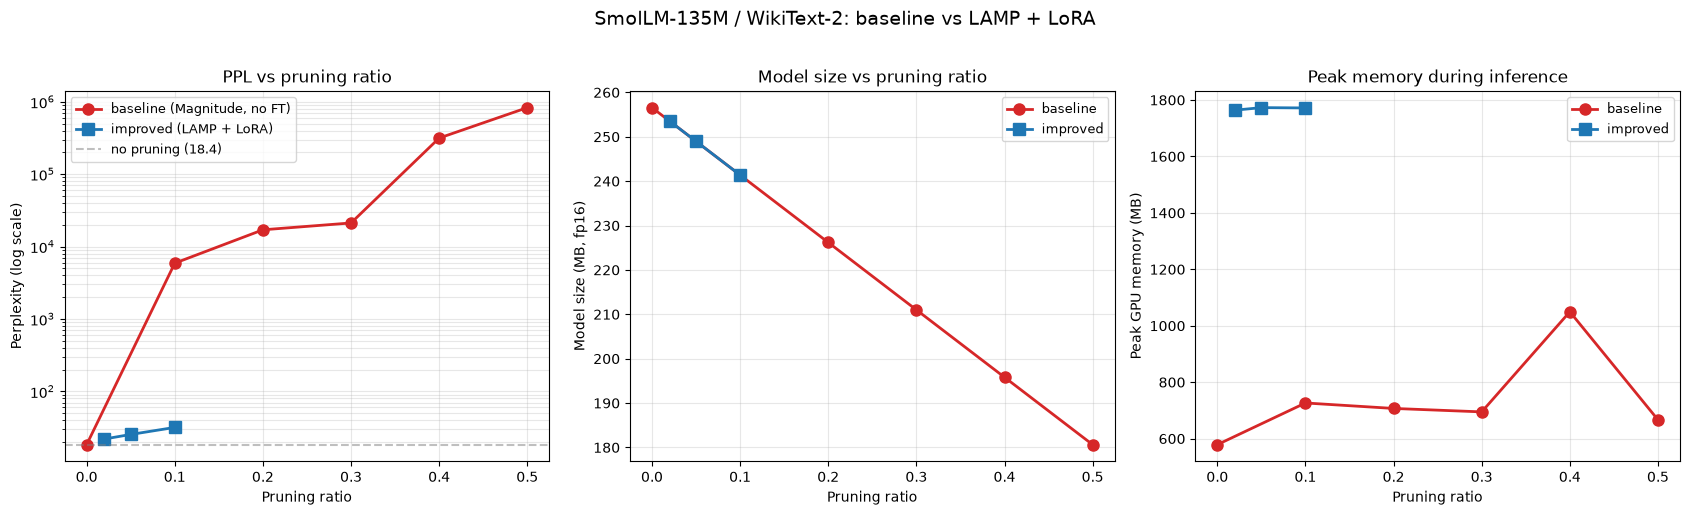

✓ Saved: logs/llm_pruning/pruning_comparison_plots.png


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# ---------- 1. PPL (логарифмическая шкала) ----------
ax = axes[0]
ax.plot(df_base["ratio"], df_base["ppl"], "o-", color="tab:red",
        linewidth=2, markersize=8, label="baseline (Magnitude, no FT)")
ax.plot(df_imp["ratio"], df_imp["ppl"], "s-", color="tab:blue",
        linewidth=2, markersize=8, label="improved (LAMP + LoRA)")

ppl_ref = df_base.loc[df_base["ratio"] == 0.0, "ppl"].values
if len(ppl_ref):
    ax.axhline(ppl_ref[0], color="gray", ls="--", alpha=0.5,
               label=f"no pruning ({ppl_ref[0]:.1f})")

ax.set_yscale("log")
ax.set_xlabel("Pruning ratio")
ax.set_ylabel("Perplexity (log scale)")
ax.set_title("PPL vs pruning ratio")
ax.grid(True, alpha=0.3, which="both")
ax.legend(fontsize=9)

# ---------- 2. Размер модели ----------
ax = axes[1]
ax.plot(df_base["ratio"], df_base["model_size_mb"], "o-",
        color="tab:red", linewidth=2, markersize=8, label="baseline")
ax.plot(df_imp["ratio"], df_imp["model_size_mb"], "s-",
        color="tab:blue", linewidth=2, markersize=8, label="improved")

ax.set_xlabel("Pruning ratio")
ax.set_ylabel("Model size (MB, fp16)")
ax.set_title("Model size vs pruning ratio")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)

# ---------- 3. Пиковая память ----------
ax = axes[2]
ax.plot(df_base["ratio"], df_base["peak_mem_mb"], "o-",
        color="tab:red", linewidth=2, markersize=8, label="baseline")
ax.plot(df_imp["ratio"], df_imp["peak_mem_mb"], "s-",
        color="tab:blue", linewidth=2, markersize=8, label="improved")

ax.set_xlabel("Pruning ratio")
ax.set_ylabel("Peak GPU memory (MB)")
ax.set_title("Peak memory during inference")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)

plt.suptitle("SmolLM-135M / WikiText-2: baseline vs LAMP + LoRA",
             fontsize=14, y=1.02)
plt.tight_layout()
out_png = os.path.join(LOG_DIR, "pruning_comparison_plots.png")
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {out_png}")

## show results

In [10]:
df = pd.DataFrame(all_rows)
out_csv = os.path.join(LOG_DIR, "ppl_memory.csv")
df.to_csv(out_csv, index=False)
print(f"\n✓ Saved: {os.path.abspath(out_csv)}")
print(df.to_string(index=False))

df_ok = df.dropna(subset=["ppl"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# PPL
axes[0].plot(df_ok["ratio"], df_ok["ppl"], "o-", linewidth=2, markersize=8)
axes[0].set_xlabel("Pruning ratio")
axes[0].set_ylabel("Perplexity (lower is better)")
axes[0].set_title("PPL vs pruning ratio")
axes[0].grid(True, alpha=0.3)

# Model size
axes[1].plot(df_ok["ratio"], df_ok["model_size_mb"], "s-",
             linewidth=2, markersize=8, color="tab:orange")
axes[1].set_xlabel("Pruning ratio")
axes[1].set_ylabel("Model size (MB, fp16)")
axes[1].set_title("Model size vs pruning ratio")
axes[1].grid(True, alpha=0.3)

# Peak memory during inference
axes[2].plot(df_ok["ratio"], df_ok["peak_mem_mb"], "^-",
             linewidth=2, markersize=8, color="tab:green")
axes[2].set_xlabel("Pruning ratio")
axes[2].set_ylabel("Peak GPU memory (MB)")
axes[2].set_title("Peak memory during inference")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
out_png = os.path.join(LOG_DIR, "ppl_memory_plots.png")
plt.savefig(out_png, dpi=150, bbox_inches="tight")
plt.show()
print(f"✓ Saved: {out_png}")

NameError: name 'all_rows' is not defined